In [5]:
!pip install pandas

import pandas as pd
import zipfile
import os



matches_df = pd.read_csv('../ipl_data/ipl_ball_by_ball_2008_2026.csv')

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
C:\Users\p.v.s vinay\AppData\Local\Temp\ipykernel_28192\2462827300.py:9: DtypeWarning: Columns (0: review_by, 1: review_decision) have mixed types. Specify dtype option on import or set low_memory=False.
  matches_df = pd.read_csv('../ipl_data/ipl_ball_by_ball_2008_2026.csv')


In [6]:

kolkata_team = "Kolkata Knight Riders"
opponent_teams = ["Royal Challengers Bengaluru", "Royal Challengers Bangalore", "Chennai Super Kings", "Mumbai Indians"]
home_grounds = ["Eden Gardens", "Chinnaswamy", "Chidambaram", "Wankhede"]

match_records = []

for match_id, group in matches_df.groupby("match_id", sort=False):
    teams = pd.unique(group[["batting_team", "bowling_team"]].to_numpy().ravel())
    teams = [team for team in teams if pd.notna(team)]

    if len(teams) < 2:
        continue

    team1, team2 = teams[:2]
    team_runs = group.groupby("batting_team")["total_runs"].sum()
    team1_runs = int(team_runs.get(team1, 0))
    team2_runs = int(team_runs.get(team2, 0))

    if team1_runs > team2_runs:
        winner = team1
    elif team2_runs > team1_runs:
        winner = team2
    else:
        winner = "Tie"

    match_records.append({
        "match_id": match_id,
        "season": group["season"].iloc[0],
        "date": group["date"].iloc[0],
        "venue": group["venue"].iloc[0],
        "team1": team1,
        "team2": team2,
        "team1_runs": team1_runs,
        "team2_runs": team2_runs,
        "winner": winner
    })

match_summary_df = pd.DataFrame(match_records)

is_kkr_match = (
    ((match_summary_df["team1"] == kolkata_team) & (match_summary_df["team2"].isin(opponent_teams))) |
    ((match_summary_df["team2"] == kolkata_team) & (match_summary_df["team1"].isin(opponent_teams)))
)

filtered_df = match_summary_df[is_kkr_match].copy()


In [7]:


venue_pattern = "|".join(home_grounds)
filtered_df = filtered_df[filtered_df["venue"].str.contains(venue_pattern, case=False, na=False)]

In [8]:

extracted_data = []

for _, row in filtered_df.iterrows():
    if row["team1"] == kolkata_team:
        runs = row.get("team1_runs", 0)
    else:
        runs = row.get("team2_runs", 0)
        
    if row["winner"] == kolkata_team:
        win_loss = "Win"
    elif pd.isna(row["winner"]) or row["winner"] == "Tie":
        win_loss = "Tie/No Result"
    else:
        win_loss = "Loss"
    is_home = "Eden Gardens" in str(row["venue"])  
    extracted_data.append({
        "team": kolkata_team,
        "ground": row["venue"],
        "runs": runs,
        "win/loss": win_loss,
        "is_home": is_home
    })

result_df = pd.DataFrame(extracted_data)
display(result_df)


,team,ground,runs,win/loss,is_home
0,Kolkata Knight Riders,M Chinnaswamy Stadium,222,Win,False
1,Kolkata Knight Riders,"MA Chidambaram Stadium, Chepauk",147,Loss,False
2,Kolkata Knight Riders,Eden Gardens,137,Loss,True
3,Kolkata Knight Riders,Eden Gardens,129,Win,True
4,Kolkata Knight Riders,Wankhede Stadium,67,Loss,False
...,...,...,...,...,...
74,Kolkata Knight Riders,"MA Chidambaram Stadium, Chepauk",107,Win,False
75,Kolkata Knight Riders,Eden Gardens,179,Loss,True
76,Kolkata Knight Riders,Wankhede Stadium,220,Loss,False
77,Kolkata Knight Riders,"MA Chidambaram Stadium, Chepauk",160,Loss,False


In [9]:
# --- Compare KKR Batting Performance: Home vs Outside Home ---

# Group the existing result_df by 'is_home' to compare metrics
batting_comparison = result_df.groupby("is_home").agg(
    matches_played=("runs", "count"),
    total_runs=("runs", "sum"),
    avg_runs_per_match=("runs", "mean"),
    wins=("win/loss", lambda x: (x == "Win").sum()),
    losses=("win/loss", lambda x: (x == "Loss").sum()),
    ties_no_result=("win/loss", lambda x: (x == "Tie/No Result").sum())
).reset_index()

# Map boolean 'is_home' to descriptive location labels
batting_comparison["Location"] = batting_comparison["is_home"].map({
    True: "Home (Eden Gardens)", 
    False: "Outside Home (Away/Neutral)"
})

# Reorder columns for a clean presentation
batting_comparison = batting_comparison[[
    "Location", "matches_played", "total_runs", 
    "avg_runs_per_match", "wins", "losses", "ties_no_result"
]]

print("--- KKR Home vs Outside Home Batting & Match Summary ---")
display(batting_comparison)

--- KKR Home vs Outside Home Batting & Match Summary ---


,Location,matches_played,total_runs,avg_runs_per_match,wins,losses,ties_no_result
0,Outside Home (Away/Neutral),43,6683,155.418605,15,28,0
1,Home (Eden Gardens),36,5846,162.388889,17,19,0


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


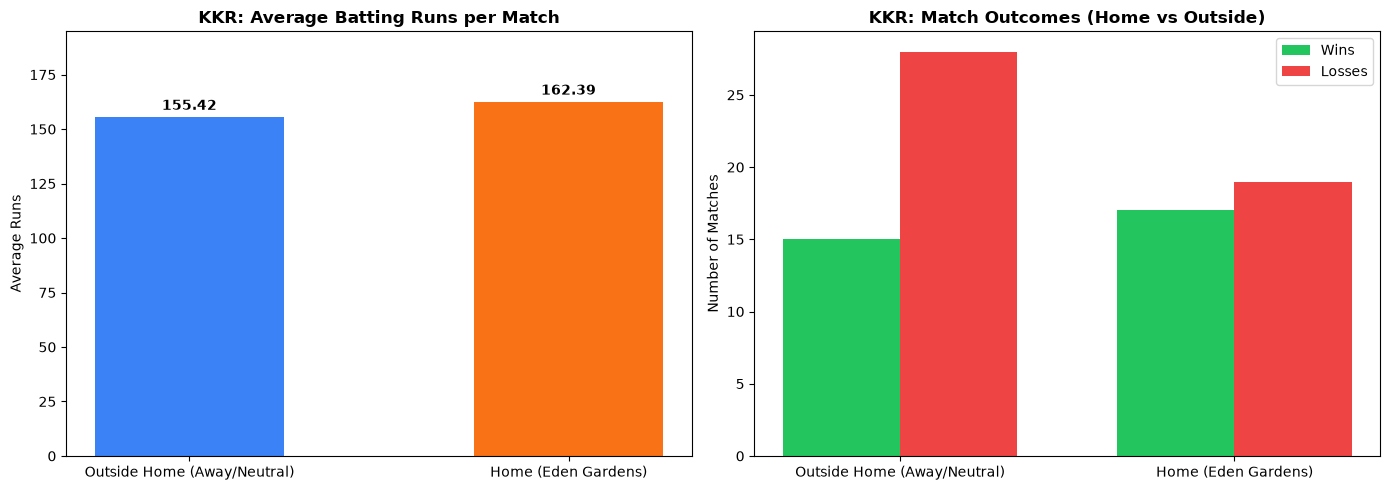

In [10]:
# --- Visualization: Home vs Outside Home Batting & Match Performance ---
!pip install matplotlib
import matplotlib.pyplot as plt

# Prepare data for plotting
locations = batting_comparison["Location"]
avg_runs = batting_comparison["avg_runs_per_match"]
wins = batting_comparison["wins"]
losses = batting_comparison["losses"]

# Create a figure with 2 subplots side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Average Runs per Match
bars1 = ax1.bar(locations, avg_runs, color=['#3b82f6', '#f97316'], width=0.5)
ax1.set_title("KKR: Average Batting Runs per Match", fontsize=12, fontweight='bold')
ax1.set_ylabel("Average Runs", fontsize=10)
ax1.set_ylim(0, max(avg_runs) * 1.2)

# Add data labels on top of bars
for bar in bars1:
    height = bar.get_height()
    ax1.annotate(f'{height:.2f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # 3 points vertical offset
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot 2: Wins vs Losses Breakdown
x = range(len(locations))
width = 0.35

bars_wins = ax2.bar([i - width/2 for i in x], wins, width, label='Wins', color='#22c55e')
bars_losses = ax2.bar([i + width/2 for i in x], losses, width, label='Losses', color='#ef4444')

ax2.set_title("KKR: Match Outcomes (Home vs Outside)", fontsize=12, fontweight='bold')
ax2.set_ylabel("Number of Matches", fontsize=10)
ax2.set_xticks(list(x))
ax2.set_xticklabels(locations)
ax2.legend()

# Layout adjustment and display
plt.tight_layout()
plt.show()